<a href="https://colab.research.google.com/github/rochankulkarni/my_project/blob/main/API_Shield_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# API Shield
## Defensive network-flow classification with CICIDS2017

The objective is to flag completed network flows as benign or malicious for analyst review. The input consists of packet counts, byte volumes, packet lengths, timing statistics, and TCP flag counts. CICIDS2017 contains labeled flows generated with CICFlowMeter in a controlled environment. The files do not provide the HTTP request metadata needed to validate API-level detection.

### Literature and model choices

Sharafaldin, Lashkari and Ghorbani (2018) describe the benchmark's labeled traffic and flow features. We compare a regularized linear baseline, a bagged tree ensemble, and a boosted tree ensemble to test whether nonlinear relationships improve detection. We use average precision for model selection because attacks and benign flows are unevenly represented. At the default classifier threshold, we report accuracy, precision, recall, F1, false positive rate, and confusion matrices.

- [UNB CICIDS2017 dataset and original study reference](https://www.unb.ca/cic/datasets/ids-2017.html)
- [Logistic regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression), [random forests](https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees), and [histogram gradient boosting](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting)


## Previous Colab run

These are the original random-holdout scores from the submitted `api_shield_results.zip`.

| Model | Accuracy | Attack recall | F1 | Average precision |
|---|---:|---:|---:|---:|
| Histogram gradient boosting | 99.56% | 99.50% | 0.9929 | 0.9994 |
| Random forest | 99.49% | 99.17% | 0.9917 | 0.9994 |
| Logistic regression | 85.36% | 94.05% | 0.7986 | 0.9331 |

The previous run counted unexpected labels such as `0` and `BENI96` as attacks. This revision explicitly validates labels and reports excluded values. The revised experiments below provide separate evidence on the cleaned dataset.
The Thursday file in the previous Colab run differs from the uploaded Thursday file used for this revision. Use the six variants evaluated together below to measure PCA’s effect. Changes from the earlier run also reflect the input difference.


## 1. Locate your CSVs

**Code cell 01**

**What it does.** Finds the CSV folder, creates the output folder and sets experiment defaults.

**Imports.** `Path` handles paths. `hashlib` fingerprints files, `re` matches weekday prefixes, `platform` reports Python's version, and `shutil` makes the final ZIP. `pandas as pd` works with tables, `numpy as np` handles numerical arrays and random sampling, and `matplotlib.pyplot as plt` makes plots. `joblib` saves the fitted model and `sklearn` supplies its version string. `warnings` is imported but unused.

| Code | What to say |
|---|---|
| `DATA_OVERRIDE = None` | Enable automatic folder detection. Set it to a folder path to override that choice. |
| `Path(...)`, `.glob('*.csv')` | Represent a folder and search its immediate children for CSVs. The Drive candidate works when Drive is already mounted. |
| `any(...)`, `max(..., key=lambda ...)` | Keep folders that have CSVs and choose the one with the largest CSV count. The lambda computes the count for each candidate. It falls back to `data` if none match. |
| `mkdir(exist_ok=True)` | Create the results folder and allow it to already exist. |
| `SEED = 42` | Make the split and random sampling repeatable under the same inputs and environment. |
| `CAP_PER_FILE_CLASS = 12_000` | Retain up to 12,000 benign and 12,000 attack records per distinct file before deduplication. Full valid-label counts are audited before sampling. |
| `CHUNK_SIZE = 40_000` | Read 40,000 rows at a time to manage memory. This does not limit the total rows read. |
| `print(f'...')`, `.__version__` | Insert values into a formatted string and log the folder and software versions. |

**Viva prompt.** “What happens if no folder contains CSV files?” → Setup falls back to `data`. The next cell raises a clear error if it finds no CSVs there. Runtime uploads disappear when Colab resets.

In [ ]:
from pathlib import Path
import hashlib
import platform
import re
import shutil
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

DATA_OVERRIDE = None
candidates = [
    Path('/content'),
    Path('/'),
    Path('/content/drive/MyDrive/API_Shield/data'),
    Path('data'),
]
if DATA_OVERRIDE is None:
    available = [directory for directory in candidates if any(directory.glob('*.csv'))]
    DATA_DIR = max(available, key=lambda directory: sum(1 for _ in directory.glob('*.csv')), default=Path('data'))
else:
    DATA_DIR = Path(DATA_OVERRIDE)

OUTPUT_DIR = Path('api_shield_results')
OUTPUT_DIR.mkdir(exist_ok=True)
SEED = 42
CAP_PER_FILE_CLASS = 12_000
CHUNK_SIZE = 40_000
print(f'CSV folder: {DATA_DIR} ({len(list(DATA_DIR.glob("*.csv")))} CSV files)')
print(f'Python {platform.python_version()}, pandas {pd.__version__}, NumPy {np.__version__}, scikit-learn {sklearn.__version__}')

CSV folder: /content (7 CSV files)
Python 3.13.18, pandas 2.2.3, NumPy 2.4.6, scikit-learn 1.6.1


## 2. Audit, clean, and explore

**Code cell 02**

**What it does.** Reads distinct CSVs, validates labels, cleans numeric values, builds features, and creates two datasets plus audit tables.

**Import.** `Counter` from `collections` counts labels across chunks. This cell also uses `Path` objects, `hashlib`, `re`, `np`, and `pd` from setup.

| Code | What to say |
|---|---|
| `CORE_FEATURES`, `DERIVED`, `FEATURES` | The model starts with 34 selected flow measurements and adds three computed features. Identifiers, timestamps, family, source file and capture day are outside the model feature list. |
| `KNOWN_FAMILIES`, `capture_day()` | The set defines allowed labels. The function uses a case-insensitive weekday regex at the beginning of the filename to group captures. IAT means inter-arrival time. |
| `sorted(...)`, `is_file()`, `FileNotFoundError` | Visit real CSV files in a consistent order and stop with a useful message if none exist. |
| `open('rb')`, `file_digest(..., 'sha256')` | Read exact bytes and fingerprint the entire file. A repeated digest is recorded in the audit and skipped with `continue`. The context manager closes the file. |
| `pd.read_csv(..., chunksize=..., usecols=...)` | Read selected columns in chunks. UTF-8 with BOM support handles the text format. Undecodable characters are replaced. Header whitespace is stripped, and missing required columns trigger an error. |
| `raw.head(5).copy()` | Store a small preview from the first input chunk. |
| `.astype('string').str.strip().str.upper()`, `.str.replace(...)` | Standardize label case, spacing and web-attack separators. `.isin()` accepts only known labels. The inverse mask `~valid` identifies rejects for the audit. |
| `pd.to_numeric(..., errors='coerce')` | Convert feature values to numbers and mark failed conversions as missing. `.replace()`, `.mask()` and `.lt(0)` also mark infinity and negative values as missing. `float32` reduces memory usage. |
| `Total Packets`, `Total Bytes`, `Bytes per Packet` | Add forward and backward counts or byte lengths, then divide bytes by packets. `.where(...gt(0))` makes a zero denominator missing. |
| `.isna().sum().sum()`, `family.ne('BENIGN')` | Count all missing feature cells in a chunk. Encode benign as 0 and any accepted attack label as 1. Keep the original family for analysis. |
| `rng.random()`, `concat()`, `sort_values().groupby().head()` | Give each row a random priority and keep the lowest priorities per class within each file. Keeping only the best priorities so far supports sampling across chunks. |
| `.notna().any(axis=1)` | Exclude rows that have no usable feature at all. Partial missingness remains for the later model pipeline. |
| `.duplicated(..., keep=False)` and `.transform('nunique').gt(1)` | Mark all rows in repeated feature groups and identify groups with both binary labels. `dropna=False` lets matching missing values participate in grouping. Remove all rows in conflicting groups. |
| `.drop_duplicates(FEATURES)` | Keep one row per feature vector for the random split. For the day experiment, keep one per **day plus feature vector**, so the same pattern can remain in different days until overlap removal at evaluation. |
| `.to_csv(..., index=False)` | Export label rejects, per-file audit and raw valid-family counts without adding DataFrame row indices as a column. |

**Verified run.** Eight uploads, seven distinct files, 2,660,377 raw rows, 134,002 retained rows with features, 13,903 conflicting rows removed, 19,934 further duplicates removed, and 100,165 final random-split flows. Exact duplicate **columns** were not scanned here. The training pipeline removes constant columns later.

In [ ]:
from collections import Counter

CORE_FEATURES = [
    'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
    'Total Length of Fwd Packets', 'Total Length of Bwd Packets',
    'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean',
    'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min',
    'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s',
    'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max',
    'Fwd IAT Total', 'Bwd IAT Total', 'Fwd Packets/s', 'Bwd Packets/s',
    'Min Packet Length', 'Max Packet Length', 'Packet Length Mean',
    'Packet Length Std', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count',
    'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count',
    'Active Mean', 'Idle Mean',
]
KNOWN_FAMILIES = {
    'BENIGN', 'DDOS', 'PORTSCAN', 'BOT', 'INFILTRATION', 'FTP-PATATOR',
    'SSH-PATATOR', 'DOS SLOWLORIS', 'DOS SLOWHTTPTEST', 'DOS HULK',
    'DOS GOLDENEYE', 'HEARTBLEED', 'WEB ATTACK BRUTE FORCE',
    'WEB ATTACK XSS', 'WEB ATTACK SQL INJECTION',
}

def capture_day(filename):
    match = re.match(r'(Monday|Tuesday|Wednesday|Thursday|Friday)', filename, re.IGNORECASE)
    return match.group(1).title() if match else 'Unknown'

DERIVED = ['Total Packets', 'Total Bytes', 'Bytes per Packet']
FEATURES = CORE_FEATURES + DERIVED

paths = sorted(path for path in DATA_DIR.glob('*.csv') if path.is_file())
if not paths:
    raise FileNotFoundError(f'No CSV files in {DATA_DIR}')

rng = np.random.default_rng(SEED)
retained_frames, audit_records, family_records = [], [], []
seen_digests = {}
rejected_labels = []
raw_preview = None
for path in paths:
    with path.open('rb') as handle:
        digest = hashlib.file_digest(handle, 'sha256').hexdigest()
    audit = {'file': path.name, 'sha256': digest, 'duplicate_of': seen_digests.get(digest, '')}
    audit_records.append(audit)
    if digest in seen_digests:
        continue
    seen_digests[digest] = path.name
    retained = None
    counts = Counter()
    audit.update(raw_rows=0, dropped_labels=0, missing_feature_values=0)
    for raw in pd.read_csv(
        path, chunksize=CHUNK_SIZE, encoding='utf-8-sig', encoding_errors='replace',
        usecols=lambda name: name.strip() in {*CORE_FEATURES, 'Label'},
        low_memory=False,
    ):
        raw.columns = raw.columns.str.strip()
        missing = set(CORE_FEATURES + ['Label']) - set(raw.columns)
        if missing:
            raise ValueError(f'{path.name} is missing columns: {sorted(missing)}')
        audit['raw_rows'] += len(raw)
        if raw_preview is None:
            raw_preview = raw.head(5).copy()
        family = (
            raw['Label'].astype('string').str.strip().str.upper()
            .str.replace(r'^WEB ATTACK[^A-Z0-9]+', 'WEB ATTACK ', regex=True)
            .str.replace(r'\s+', ' ', regex=True)
        )
        valid = family.isin(KNOWN_FAMILIES)
        audit['dropped_labels'] += int((~valid).sum())
        rejected_labels.extend(
            {'file': path.name, 'label': label, 'rows': int(count)}
            for label, count in family.loc[~valid].fillna('<MISSING>').value_counts().items()
        )
        family = family.loc[valid]
        counts.update(family.tolist())
        clean = raw.loc[valid, CORE_FEATURES].apply(pd.to_numeric, errors='coerce')
        clean = clean.replace([np.inf, -np.inf], np.nan).astype('float32')
        clean = clean.mask(~np.isfinite(clean) | clean.lt(0))
        clean['Total Packets'] = clean['Total Fwd Packets'] + clean['Total Backward Packets']
        clean['Total Bytes'] = clean['Total Length of Fwd Packets'] + clean['Total Length of Bwd Packets']
        clean['Bytes per Packet'] = clean['Total Bytes'].div(clean['Total Packets'].where(clean['Total Packets'].gt(0)))
        clean[DERIVED] = clean[DERIVED].replace([np.inf, -np.inf], np.nan)
        audit['missing_feature_values'] += int(clean[FEATURES].isna().sum().sum())
        clean['family'] = family
        clean['target'] = family.ne('BENIGN').astype('int8')
        clean['source_file'] = path.name
        clean['priority'] = rng.random(len(clean))
        retained = pd.concat([retained, clean], ignore_index=True)
        if CAP_PER_FILE_CLASS is not None:
            retained = retained.sort_values('priority').groupby('target', sort=False).head(CAP_PER_FILE_CLASS)

    audit['benign'] = counts['BENIGN']
    audit['attack'] = sum(counts.values()) - counts['BENIGN']
    audit['retained_before_dedup'] = len(retained)
    family_records.extend({'file': path.name, 'family': name, 'rows': n} for name, n in counts.items())
    retained_frames.append(retained.drop(columns='priority'))

audit_df = pd.DataFrame(audit_records)
family_df = pd.DataFrame(family_records)
combined = pd.concat(retained_frames, ignore_index=True)
combined = combined.loc[combined[FEATURES].notna().any(axis=1)].copy()
# Drop conflicting exact feature vectors and retain one record for matching duplicates.
conflicts = combined.duplicated(FEATURES, keep=False) & (
    combined.groupby(FEATURES, dropna=False, sort=False)['target'].transform('nunique').gt(1)
)
eligible = combined.loc[~conflicts].copy()
eligible['capture_day'] = eligible['source_file'].map(capture_day)
data = eligible.drop_duplicates(FEATURES).reset_index(drop=True)
day_data = eligible.drop_duplicates(['capture_day', *FEATURES]).reset_index(drop=True)
print(f'Exact duplicate rows removed from random-split population: {len(eligible) - len(data):,}')
rejected_df = pd.DataFrame(rejected_labels, columns=['file', 'label', 'rows'])
rejected_df = rejected_df.groupby(['file', 'label'], as_index=False)['rows'].sum()
rejected_df.to_csv(OUTPUT_DIR / 'rejected_labels.csv', index=False)
print(f'Conflicting rows removed: {conflicts.sum():,}')
print(f'Clean modeling rows: {len(data):,} / {len(combined):,} retained rows with features')
display(audit_df.drop(columns='sha256'))
audit_df.to_csv(OUTPUT_DIR / 'file_audit.csv', index=False)
family_df.to_csv(OUTPUT_DIR / 'raw_family_counts.csv', index=False)

Exact duplicate rows removed from random-split population: 19,898
Conflicting rows removed: 14,172
Clean modeling rows: 99,968 / 134,038 retained rows with features


,file,duplicate_of,raw_rows,dropped_labels,missing_feature_values,benign,attack,retained_before_dedup
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,,225745,0,78,97718,128027,24000
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,,286467,0,922,127537,158930,24000
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,,191033,0,288,189067,1966,13966
3,Monday-WorkingHours.pcap_ISCX.csv,,529918,0,943,529918,0,12000
4,Thursday-WorkingHours-Afternoon-Infilteration....,,574581,69,868,574440,72,12072
5,Tuesday-WorkingHours.pcap_ISCX.csv,,445909,0,596,432074,13835,24000
6,Wednesday-workingHours.pcap_ISCX.csv,,692703,0,2694,440031,252672,24000


### Inspect the cleaned dataset

**Code cell 03**

**What it does.** Checks what the cleaned dataset contains and shows the effect of cleaning. No new imports. `display` is provided by the notebook environment.

- `head()` previews the first five rows. The raw preview contains the selected input columns.
- `shape` gives rows and columns. The verified run has **100,165 rows and 41 columns**, with **37 candidate model features** and four label or metadata columns.
- `columns.tolist()` prints column names. `info()` prints types and non-null counts.
- `describe().T.round(3)` summarizes numeric features, switches features to rows and rounds the display.
- `duplicated(subset=FEATURES).sum()` counts repeated feature vectors after each group's first occurrence. The before-cleaning count can include repeats from conflicting groups. The post-cleaning count is zero for `data`.
- `isnull()` and `isna()` are equivalent null checks here. One displays example Boolean flags. The other uses `.sum()` to count missing entries per column, then saves `missing_counts.csv`.
- Sorting the rejected-label audit by `rows` shows the most common rejected values, if any.

**Viva prompt.** “Why do missing values remain?” → We fit median replacement inside each training fold so validation or test values cannot influence the median.

In [ ]:
print('Input preview (selected columns, first distinct file)')
display(raw_preview.head())
print('Cleaned modeling table')
display(data.head())
print(f'Shape: {data.shape}')
print(f'Columns ({len(data.columns)}):', data.columns.tolist())
data.info()
display(data[FEATURES].describe().T.round(3))
print(f'Exact feature duplicates before cleaning: {combined.duplicated(subset=FEATURES).sum():,}')
print(f'Exact feature duplicates after cleaning: {data.duplicated(subset=FEATURES).sum():,}')
print('Missing-value flags and totals')
display(data[FEATURES[:8]].isnull().head())
missing_counts = data.isna().sum().rename('missing_count').to_frame()
display(missing_counts)
missing_counts.to_csv(OUTPUT_DIR / 'missing_counts.csv')
print(f'Unexpected or missing labels excluded: {rejected_df.rows.sum():,}')
display(rejected_df.sort_values('rows', ascending=False).head(15))

Input preview (selected columns, first distinct file)


,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,...,Packet Length Std,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,Active Mean,Idle Mean,Label
0,3,2,0,12,0,6,6,6.0,0.0,0,...,0.0,0,0,0,0,1,0,0.0,0.0,BENIGN
1,109,1,1,6,6,6,6,6.0,0.0,6,...,0.0,0,0,0,0,1,1,0.0,0.0,BENIGN
2,52,1,1,6,6,6,6,6.0,0.0,6,...,0.0,0,0,0,0,1,1,0.0,0.0,BENIGN
3,34,1,1,6,6,6,6,6.0,0.0,6,...,0.0,0,0,0,0,1,1,0.0,0.0,BENIGN
4,3,2,0,12,0,6,6,6.0,0.0,0,...,0.0,0,0,0,0,1,0,0.0,0.0,BENIGN


Cleaned modeling table


,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,...,URG Flag Count,Active Mean,Idle Mean,Total Packets,Total Bytes,Bytes per Packet,family,target,source_file,capture_day
0,57.0,3.0,1.0,4.0,4.0,4.0,0.0,1.333333,2.309401,4.0,...,0.0,0.0,0.0,4.0,8.0,2.000000,BENIGN,0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Friday
1,9845733.0,5.0,0.0,30.0,0.0,6.0,6.0,6.000000,0.000000,0.0,...,0.0,1986.0,9843747.0,5.0,30.0,6.000000,DDOS,1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Friday
2,10195566.0,8.0,9.0,771.0,4713.0,422.0,0.0,96.375000,150.901993,1460.0,...,0.0,78176.0,9996305.0,17.0,5484.0,322.588226,BENIGN,0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Friday
3,7107579.0,4.0,0.0,24.0,0.0,6.0,6.0,6.000000,0.000000,0.0,...,0.0,692.0,7106887.0,4.0,24.0,6.000000,DDOS,1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Friday
4,101459424.0,5.0,9.0,11613.0,62.0,11595.0,0.0,2322.600098,5183.429688,20.0,...,1.0,26668.0,50100000.0,14.0,11675.0,833.928589,BENIGN,0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Friday


Shape: (99968, 41)
Columns (41): ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Fwd IAT Total', 'Bwd IAT Total', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'Active Mean', 'Idle Mean', 'Total Packets', 'Total Bytes', 'Bytes per Packet', 'family', 'target', 'source_file', 'capture_day']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99968 entries, 0 to 99967
Data columns (total 41 columns):
 #   Column                       Non-Null Count  Dtype

,count,mean,std,min,25%,50%,75%,max
Flow Duration,99964.0,1.904113e+07,3.605360e+07,0.000,23703.000,205323.000,1.004401e+07,1.199999e+08
Total Fwd Packets,99968.0,8.345000e+00,1.421430e+02,1.000,2.000,3.000,7.000000e+00,3.261300e+04
Total Backward Packets,99968.0,9.084000e+00,1.831190e+02,0.000,1.000,2.000,6.000000e+00,4.300800e+04
Total Length of Fwd Packets,99968.0,9.358840e+02,1.658606e+04,0.000,30.000,76.000,3.620000e+02,2.866110e+06
Total Length of Bwd Packets,99968.0,9.528797e+03,4.081767e+05,0.000,46.000,188.000,3.679000e+03,9.696822e+07
Fwd Packet Length Max,99968.0,3.378750e+02,1.160735e+03,0.000,20.000,42.000,3.090000e+02,2.336000e+04
Fwd Packet Length Min,99968.0,2.205100e+01,9.146300e+01,0.000,0.000,0.000,3.600000e+01,1.983000e+03
Fwd Packet Length Mean,99968.0,9.379300e+01,3.068300e+02,0.000,8.667,38.000,5.500000e+01,5.940857e+03
Fwd Packet Length Std,99968.0,1.186140e+02,4.694650e+02,0.000,0.000,0.000,9.819000e+01,7.049469e+03
Bwd Packet Length Max,99968.0,1.355449e+03,2.499833e+03,0.000,20.000,114.000,1.448000e+03,1.592800e+04


Exact feature duplicates before cleaning: 33,665
Exact feature duplicates after cleaning: 0
Missing-value flags and totals


,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False


,missing_count
Flow Duration,4
Total Fwd Packets,0
Total Backward Packets,0
Total Length of Fwd Packets,0
Total Length of Bwd Packets,0
Fwd Packet Length Max,0
Fwd Packet Length Min,0
Fwd Packet Length Mean,0
Fwd Packet Length Std,0
Bwd Packet Length Max,0


Unexpected or missing labels excluded: 69


,file,label,rows
17,Thursday-WorkingHours-Afternoon-Infilteration....,<MISSING>,36
1,Thursday-WorkingHours-Afternoon-Infilteration....,0,13
6,Thursday-WorkingHours-Afternoon-Infilteration....,20,2
0,Thursday-WorkingHours-Afternoon-Infilteration....,-1,1
2,Thursday-WorkingHours-Afternoon-Infilteration....,1,1
4,Thursday-WorkingHours-Afternoon-Infilteration....,11,1
3,Thursday-WorkingHours-Afternoon-Infilteration....,1024,1
7,Thursday-WorkingHours-Afternoon-Infilteration....,20833.33333,1
5,Thursday-WorkingHours-Afternoon-Infilteration....,2,1
9,Thursday-WorkingHours-Afternoon-Infilteration....,24,1


### Create the stratified random split

**Code cell 04**

**What it does.** Creates the random training and holdout sets for the first experiment.

**Import.** `train_test_split` from `sklearn.model_selection` partitions rows.

- `value_counts().reindex([0, 1], fill_value=0).min()` checks the smaller class. Adding missing classes with a count of zero prevents an absent class from passing the check.
- `test_size=.20` reserves 20% for testing. `stratify=data['target']` keeps class proportions approximately consistent, and `random_state=SEED` fixes the shuffle.
- `x_train` and `x_test` contain `FEATURES` only. `y_train` and `y_test` contain the 0/1 labels.
- The verified run has **80,132 training rows** and **20,033 test rows**. The algorithms are tuned on training data in a later cell.

**Viva prompt.** “Can the same capture day appear on both sides?” → Yes. Stratification uses the class label. The capture-day experiment tests held-out days separately.

In [ ]:
from sklearn.model_selection import train_test_split

if data['target'].value_counts().reindex([0, 1], fill_value=0).min() < 12:
    raise ValueError('At least 12 cleaned flows in each class are needed.')
train, test = train_test_split(
    data, test_size=.20, stratify=data['target'], random_state=SEED
)
x_train, y_train = train[FEATURES], train['target']
x_test, y_test = test[FEATURES], test['target']

### Plot class balance and missingness

**Code cell 05**

**What it does.** Profiles training class balance and missingness. It also shows a separate raw valid-label breakdown. No new imports. It uses pandas plotting and `plt`.

- `plt.subplots(1, 2)` makes two side-by-side axes.
- `.map({0: 'Benign', 1: 'Attack'}).value_counts()` relabels and counts training classes.
- `.isna().mean()` gives the missing fraction for each feature because Boolean values act as 0 or 1. `.nlargest(10).sort_values().mul(100)` selects the top ten and converts them to percentages for the horizontal bar chart.
- `tight_layout()`, `savefig()` and `show()` fit labels, save the PNG and display the result.
- `family_df.groupby('family')['rows'].sum()` combines raw valid-family counts across distinct files, before sampling.

**Viva prompt.** “Are the raw family counts and training class counts from the same population?” → The raw counts come before sampling and deduplication. The training chart comes after both operations and the split.

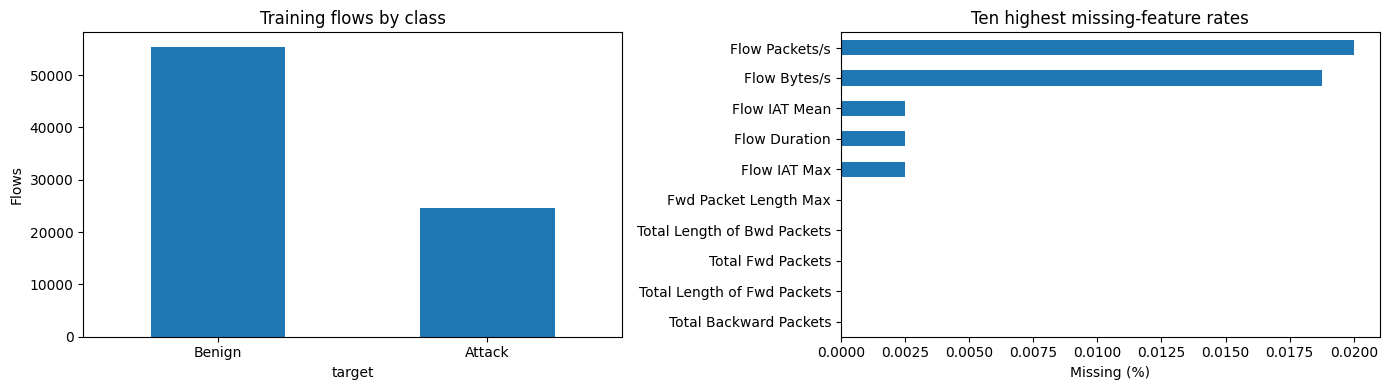

,Raw flows
family,
BENIGN,2390785
DOS HULK,231073
PORTSCAN,158930
DDOS,128027
DOS GOLDENEYE,10293
FTP-PATATOR,7938
SSH-PATATOR,5897
DOS SLOWLORIS,5796
DOS SLOWHTTPTEST,5499


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
train['target'].map({0: 'Benign', 1: 'Attack'}).value_counts().plot.bar(ax=axes[0], rot=0, title='Training flows by class')
train[FEATURES].isna().mean().nlargest(10).sort_values().mul(100).plot.barh(ax=axes[1], title='Ten highest missing-feature rates')
axes[0].set_ylabel('Flows')
axes[1].set_xlabel('Missing (%)')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'data_profile.png', dpi=160)
plt.show()
display(family_df.groupby('family')['rows'].sum().sort_values(ascending=False).to_frame('Raw flows'))

### Explore feature distributions and correlations

**Code cell 06**

**What it does.** Explores distributions, class overlap, and correlations using training data.

**Import.** `MaxNLocator` from `matplotlib.ticker` limits the number of ticks on small pair-plot axes. This cell also uses `plt`, `np` and `pd`.

| Code | What to say |
|---|---|
| `COLORS`, `LABELS`, `PLOT_FEATURES` | Store class colors, readable class names and the four features selected for display. |
| `groupby('target')`, `sample(n=min(400, len(group)), ...)` | Draw up to 400 flows per class for the pair plot. The cap controls visual clutter. |
| `np.log1p(...)` | Compute log(1 + value), allowing zeros and compressing long right tails. These transformed tables are used for visualizations. |
| `save_figure()` | Save a readable PNG, display it and close the figure object. |
| `axes.flat`, `zip(...)`, `dropna()` | Walk across subplot axes and feature names together. Skip missing values when drawing distributions. |
| `histogram_bin_edges(...)`, `density=True`, `alpha` | Use common bin edges per feature, normalize histogram area and make overlapping classes visible. |
| `boxplot(..., showfliers=False)` | Show medians, quartiles and spread. Hide extreme points in the figure for readability. The dataset is unchanged by this plotting option. |
| `enumerate()`, `row == col`, `scatter()` | Use feature histograms on the diagonal of the pair plot and two-feature scatter plots off the diagonal. |
| `.corr(method='spearman')` | Measure rank-based association on the original training columns. The scale runs from −1 to +1. |
| `imshow()`, `.iat[row, col]`, `np.isfinite()` | Draw the heatmap, retrieve each coefficient by position and annotate finite values. A constant column can produce an undefined coefficient. |

**Viva prompt.** “Does correlation prove a feature can be removed?” → No. The chart shows shared rank patterns. PCA variants test whether compression actually improves model results.

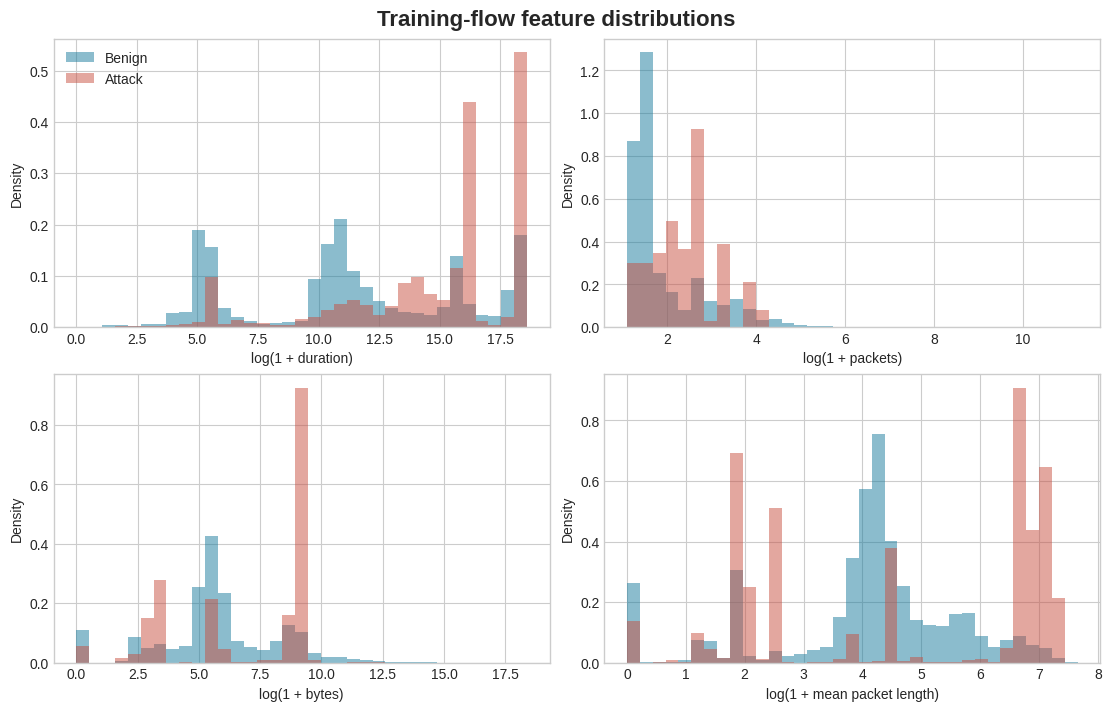

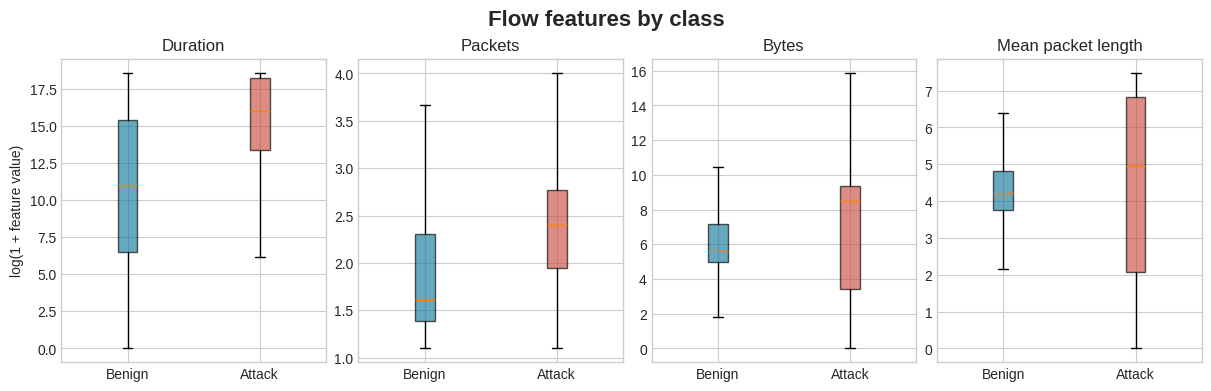

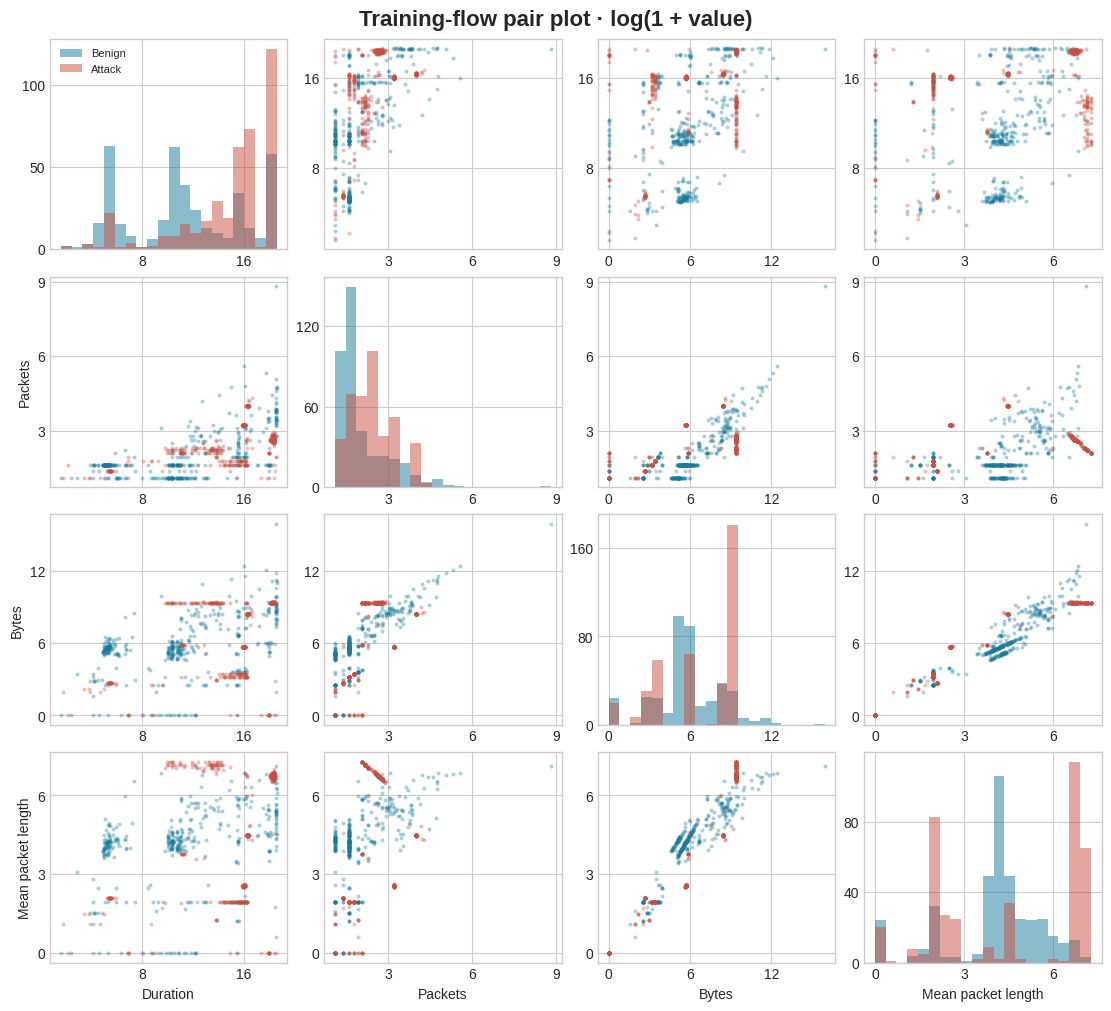

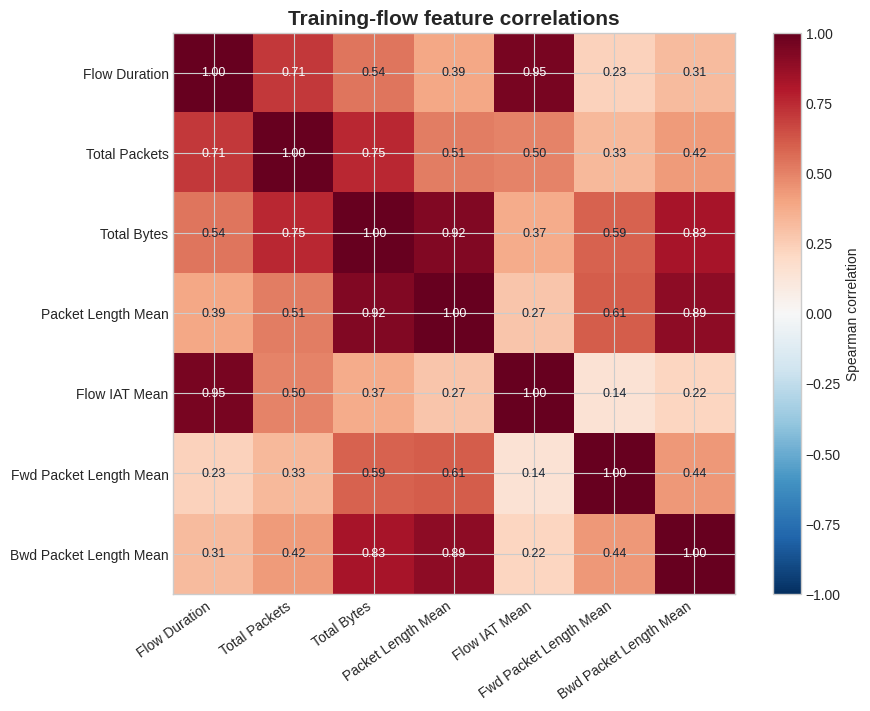

In [ ]:
from matplotlib.ticker import MaxNLocator

COLORS = {0: '#187B9D', 1: '#C85041'}
LABELS = {0: 'Benign', 1: 'Attack'}
PLOT_FEATURES = {
    'Flow Duration': 'Duration',
    'Total Packets': 'Packets',
    'Total Bytes': 'Bytes',
    'Packet Length Mean': 'Mean packet length',
}
sample = pd.concat([
    group.sample(n=min(400, len(group)), random_state=SEED)
    for _, group in train.groupby('target')
])
logged = np.log1p(train[list(PLOT_FEATURES)])
logged_sample = np.log1p(sample[list(PLOT_FEATURES)])

def save_figure(fig, filename):
    fig.savefig(OUTPUT_DIR / filename, dpi=170, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

with plt.style.context('seaborn-v0_8-whitegrid'):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
    for ax, (feature, label) in zip(axes.flat, PLOT_FEATURES.items()):
        values = logged[feature].dropna()
        edges = np.histogram_bin_edges(values, bins=35)
        for target, color in COLORS.items():
            group = logged.loc[train['target'].eq(target), feature].dropna()
            if not group.empty:
                ax.hist(group, bins=edges, density=True, alpha=.50, color=color, label=LABELS[target])
        ax.set(xlabel=f'log(1 + {label.lower()})', ylabel='Density')
    axes[0, 0].legend()
    fig.suptitle('Training-flow feature distributions', fontsize=16, fontweight='bold')
    save_figure(fig, 'feature_histograms.png')

    fig, axes = plt.subplots(1, 4, figsize=(12, 3.8), layout='constrained')
    for ax, (feature, label) in zip(axes, PLOT_FEATURES.items()):
        groups = [logged.loc[train['target'].eq(target), feature].dropna() for target in LABELS]
        boxes = ax.boxplot(groups, patch_artist=True, showfliers=False)
        for box, color in zip(boxes['boxes'], COLORS.values()):
            box.set_facecolor(color)
            box.set_alpha(.65)
        ax.set_xticks([1, 2], list(LABELS.values()))
        ax.set_title(label)
    axes[0].set_ylabel('log(1 + feature value)')
    fig.suptitle('Flow features by class', fontsize=16, fontweight='bold')
    save_figure(fig, 'feature_boxplots.png')

    variables = list(PLOT_FEATURES)
    fig, axes = plt.subplots(4, 4, figsize=(11, 10), layout='constrained')
    for row, y in enumerate(variables):
        for col, x in enumerate(variables):
            ax = axes[row, col]
            for target, color in COLORS.items():
                group = logged_sample.loc[sample['target'].eq(target)]
                if row == col:
                    edges = np.histogram_bin_edges(logged_sample[x].dropna(), bins=20)
                    ax.hist(group[x].dropna(), bins=edges, alpha=.50, color=color, label=LABELS[target])
                else:
                    ax.scatter(group[x], group[y], s=8, alpha=.36, color=color, linewidths=0)
            ax.xaxis.set_major_locator(MaxNLocator(3))
            ax.yaxis.set_major_locator(MaxNLocator(3))
            if row == 3:
                ax.set_xlabel(PLOT_FEATURES[x])
            if col == 0 and row != 0:
                ax.set_ylabel(PLOT_FEATURES[y])
    axes[0, 0].legend(fontsize=8)
    fig.suptitle('Training-flow pair plot · log(1 + value)', fontsize=16, fontweight='bold')
    save_figure(fig, 'feature_pairplot.png')

    heat_features = [*variables, 'Flow IAT Mean', 'Fwd Packet Length Mean', 'Bwd Packet Length Mean']
    corr = train[heat_features].corr(method='spearman')
    fig, ax = plt.subplots(figsize=(9, 7), layout='constrained')
    image = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=35, ha='right')
    ax.set_yticks(range(len(corr)), corr.index)
    for row in range(len(corr)):
        for col in range(len(corr)):
            value = corr.iat[row, col]
            if np.isfinite(value):
                ax.text(col, row, f'{value:.2f}', ha='center', va='center',
                        color='white' if abs(value) > .65 else '#182431', fontsize=9)
    fig.colorbar(image, ax=ax, label='Spearman correlation')
    ax.set_title('Training-flow feature correlations', fontsize=15, fontweight='bold')
    save_figure(fig, 'feature_correlation_heatmap.png')

## 3. Three models with and without PCA

**Code cell 07**

**What it does.** Tunes three classifiers, each with and without PCA, and selects the best variant using training cross-validation.

**Imports.** `clone` copies estimator settings without fitted state. `PCA` reduces dimensions. `HistGradientBoostingClassifier`, `RandomForestClassifier` and `LogisticRegression` are the models. `SimpleImputer`, `VarianceThreshold` and `StandardScaler` handle missing values, constant features and scaling. `Pipeline` chains steps. `GridSearchCV` and `StratifiedKFold` handle tuning and validation. `train_test_split` is re-imported here and was already used in the split cell.

| Code | What to say |
|---|---|
| `StratifiedKFold(n_splits=3, shuffle=True, ...)` | Rotate three class-balanced folds within the training set. |
| `LogisticRegression(...)`, `model__C` | Train a linear classifier as the baseline. Smaller C means stronger regularization. The iteration cap helps the solver finish. |
| `RandomForestClassifier(n_estimators=100, ...)` | Average 100 randomized trees. Tune tree depth and minimum samples per leaf to manage model complexity. `n_jobs=-1` uses available CPU cores. |
| `HistGradientBoostingClassifier(max_iter=100, ...)` | Bin feature values and fit small trees sequentially to improve the current model. Tune leaf count and L2 regularization. |
| `class_weight='balanced'`, `'balanced_subsample'` | Compensate for class frequency. For the forest, the balanced weights are computed from each tree's bootstrap sample. |
| `SimpleImputer(strategy='median', keep_empty_features=True)` | Learn medians from training. Keep all-empty columns in this step so the next step can remove features with no variance. |
| `VarianceThreshold()` | Default threshold 0 removes constant features. It does not detect identical columns that both vary. |
| `StandardScaler()`, `'passthrough'` | Standardize data before PCA and for the logistic baseline. Skip scaling for tree models without PCA. |
| `PCA(n_components=.95, svd_solver='full')` | Keep enough components to meet a 95% variance target. Full SVD computes the directions from standardized training features. |
| `Pipeline([...])`, `clone(model)` | Fit transformations and a fresh estimator together inside each training fold. Test examples receive the trained transformations. |
| `model__...`, `GridSearchCV(..., scoring='average_precision')` | Double underscores address arguments inside the named pipeline step. Search ranks settings by mean validation average precision, a threshold-independent summary of precision and recall. |
| `return_train_score=True`, `error_score='raise'`, `.fit(x_train, y_train)` | Record train scores to inspect the train–validation gap, surface errors, and tune using the training set. The best configuration is refitted on the full training partition by default. |
| `best_score_`, `best_params_`, `cv_results_` | Retrieve best mean validation AP, the chosen settings and details for every candidate. `max(..., key=...)` picks the highest-scoring variant across the six searches. |

**Viva answer.** “We chose histogram gradient boosting without PCA because it had the best mean CV average precision. The 20% test set was kept separate from tuning.”

In [ ]:
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
models = {
    'Logistic regression': (
        LogisticRegression(class_weight='balanced', max_iter=1500, random_state=SEED),
        {'model__C': [0.1, 1.0, 10.0]}, StandardScaler(),
    ),
    'Random forest': (
        RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED),
        {'model__max_depth': [12, None], 'model__min_samples_leaf': [2, 8]}, 'passthrough',
    ),
    'Histogram gradient boosting': (
        HistGradientBoostingClassifier(class_weight='balanced', max_iter=100, random_state=SEED),
        {'model__max_leaf_nodes': [15, 31], 'model__l2_regularization': [0.1, 1.0]}, 'passthrough',
    ),
}

def make_pipeline(model, scaling, use_pca=False):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('constant', VarianceThreshold()),
        ('scale', StandardScaler() if use_pca else scaling),
        ('pca', PCA(n_components=.95, svd_solver='full') if use_pca else 'passthrough'),
        ('model', clone(model)),
    ])

searches = {}
for name, (model, params, scaling) in models.items():
    for use_pca in (False, True):
        variant = f'{name} + PCA' if use_pca else name
        search = GridSearchCV(
            make_pipeline(model, scaling, use_pca), params, cv=folds,
            scoring='average_precision', return_train_score=True, error_score='raise',
        )
        search.fit(x_train, y_train)
        searches[variant] = search
        slug = variant.lower().replace(' + ', '_').replace(' ', '_')
        pd.DataFrame(search.cv_results_).to_csv(OUTPUT_DIR / f'cv_{slug}.csv', index=False)
        print(variant, round(search.best_score_, 4), search.best_params_)

winner = max(searches, key=lambda name: searches[name].best_score_)
print(f'Selected by random-split CV: {winner}')

Logistic regression 0.9511 {'model__C': 10.0}
Logistic regression + PCA 0.843 {'model__C': 0.1}
Random forest 0.9996 {'model__max_depth': None, 'model__min_samples_leaf': 2}
Random forest + PCA 0.999 {'model__max_depth': 12, 'model__min_samples_leaf': 2}
Histogram gradient boosting 0.9996 {'model__l2_regularization': 0.1, 'model__max_leaf_nodes': 31}
Histogram gradient boosting + PCA 0.9991 {'model__l2_regularization': 0.1, 'model__max_leaf_nodes': 31}
Selected by random-split CV: Histogram gradient boosting


### Evaluate and compare the six variants

**Code cell 08**

**What it does.** Evaluates the six fitted variants on the untouched random holdout, compares them visually and exports the selected pipeline.

**Imports.** `confusion_matrix` counts prediction outcomes. `accuracy_score`, `precision_score`, `recall_score`, `f1_score` and `average_precision_score` compute metrics. `ConfusionMatrixDisplay` and `PrecisionRecallDisplay` draw plots.

- `predict(x_test)` returns class labels. `predict_proba(x_test)[:, 1]` selects the score for attack class 1 across all rows.
- `labels=[0, 1]` fixes benign, then attack order. `.ravel()` flattens the 2×2 matrix to TN, FP, FN, TP. The rows are actual classes and columns are predicted classes.
- Accuracy counts all correct predictions. Precision is TP/(TP+FP). Recall is TP/(TP+FN). F1 is the harmonic mean of precision and recall. False-positive rate is FP/(TN+FP). AP uses ranked scores across thresholds. `zero_division=0` supplies zero when a metric's denominator is undefined.
- `best_index_` retrieves the chosen configuration's row from `cv_results_`. `getattr(..., 'n_components_', None)` reads the fitted PCA component count if present.
- `y_test.mean()` is the attack prevalence for 0/1 labels and gives a reference line on the precision–recall plot.
- In the per-family table, `assign()` pairs predictions with original test rows, `query('target == 1')` keeps actual attacks, and `agg(['size','sum','mean'])` gives attack support, number detected, and recall.
- `joblib.dump()` saves the fitted preprocessing and classifier together with expected feature names and the scikit-learn version. The plots and CSVs are saved separately.

**Viva answer.** “The chosen boosting model had **99.64% accuracy**, **99.55% recall**, **44 false positives** and **28 false negatives** on the random holdout. It was already selected by validation AP before this test.”

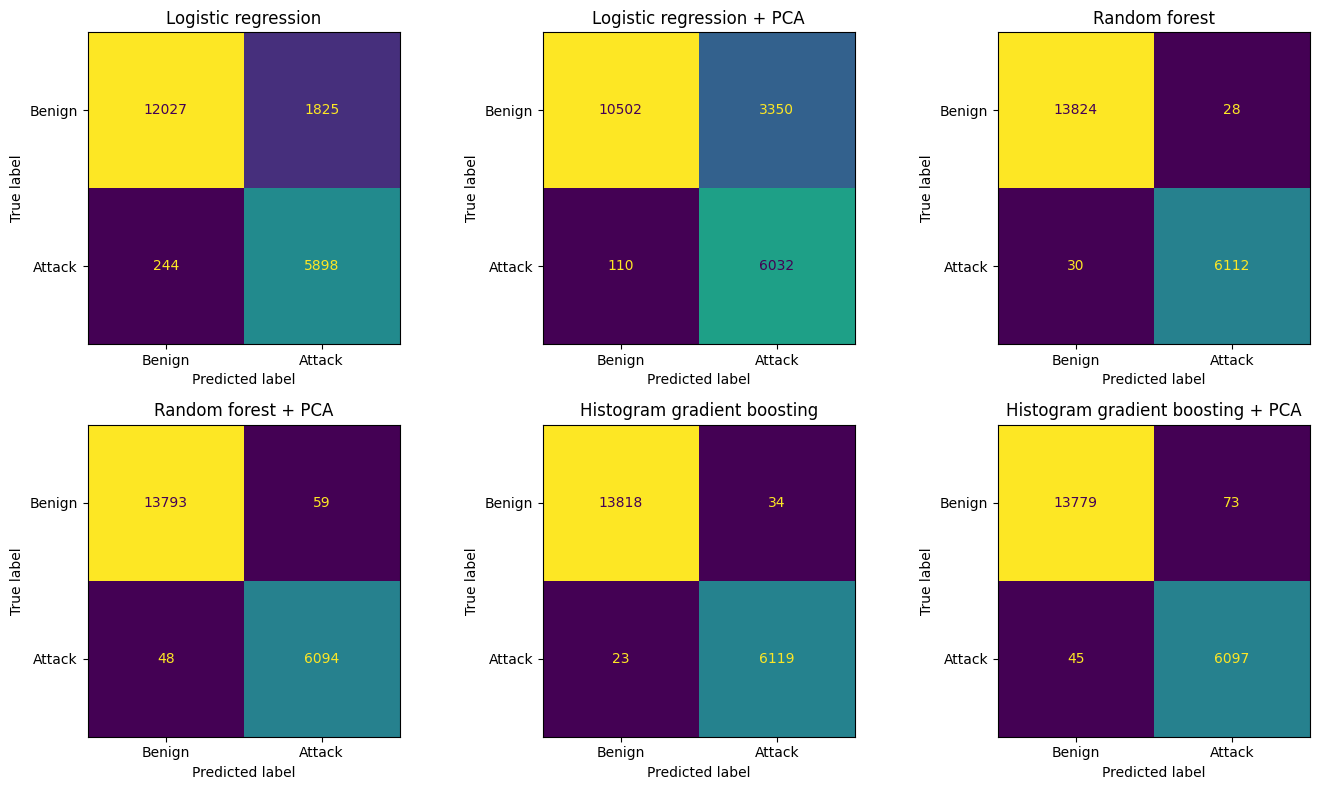

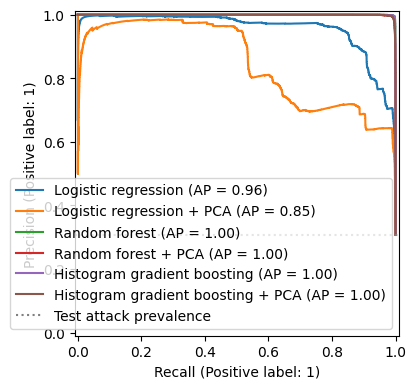

,model,pca_components,cv_train_ap,cv_validation_ap,cv_validation_ap_std,test_ap,accuracy,precision,recall,f1,false_positive_rate,tn,fp,fn,tp,parameters
4,Histogram gradient boosting,NaN,0.9999,0.9996,0.0001,0.9997,0.9971,0.9945,0.9963,0.9954,0.0025,13818,34,23,6119,"{'model__l2_regularization': 0.1, 'model__max_..."
2,Random forest,NaN,1.0000,0.9996,0.0001,0.9996,0.9971,0.9954,0.9951,0.9953,0.0020,13824,28,30,6112,"{'model__max_depth': None, 'model__min_samples..."
5,Histogram gradient boosting + PCA,16.0,0.9997,0.9991,0.0000,0.9994,0.9941,0.9882,0.9927,0.9904,0.0053,13779,73,45,6097,"{'model__l2_regularization': 0.1, 'model__max_..."
3,Random forest + PCA,16.0,0.9998,0.9990,0.0000,0.9994,0.9946,0.9904,0.9922,0.9913,0.0043,13793,59,48,6094,"{'model__max_depth': 12, 'model__min_samples_l..."
0,Logistic regression,NaN,0.9511,0.9511,0.0023,0.9569,0.8965,0.7637,0.9603,0.8508,0.1317,12027,1825,244,5898,{'model__C': 10.0}
1,Logistic regression + PCA,16.0,0.8433,0.8430,0.0025,0.8483,0.8269,0.6429,0.9821,0.7771,0.2418,10502,3350,110,6032,{'model__C': 0.1}


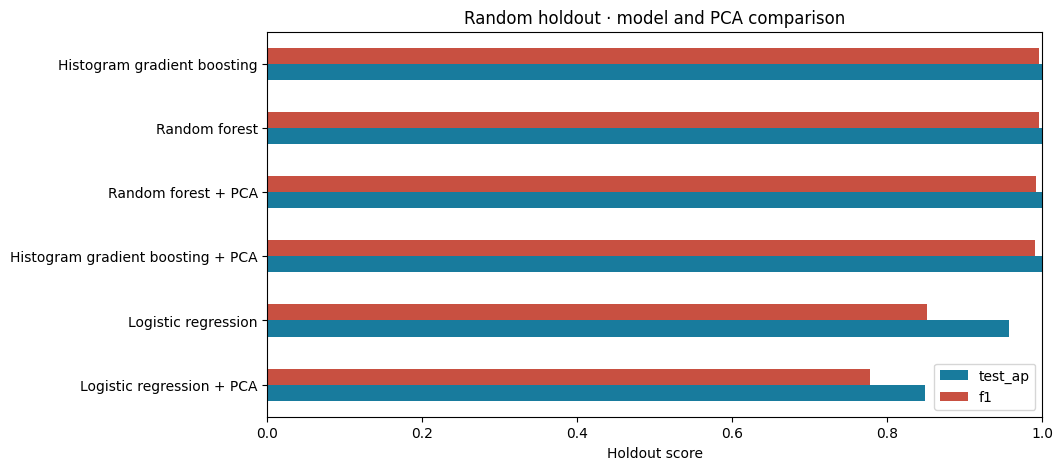

,support,detected,recall
family,,,
BOT,241,240,0.9959
DDOS,2412,2410,0.9992
DOS GOLDENEYE,91,89,0.9780
DOS HULK,1699,1694,0.9971
DOS SLOWHTTPTEST,41,41,1.0000
DOS SLOWLORIS,47,47,1.0000
FTP-PATATOR,1013,1010,0.9970
INFILTRATION,10,6,0.6000
PORTSCAN,65,65,1.0000


['api_shield_results/selected_model.joblib']

In [ ]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, accuracy_score,
    average_precision_score, confusion_matrix, f1_score, precision_score, recall_score,
)

records, predictions = [], {}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
pr_fig, pr_ax = plt.subplots(figsize=(6, 4))
for ax, (name, search) in zip(axes.flat, searches.items()):
    pred = search.predict(x_test)
    score = search.predict_proba(x_test)[:, 1]
    predictions[name] = pred
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    cv = search.cv_results_
    i = search.best_index_
    records.append({
        'model': name,
        'pca_components': getattr(search.best_estimator_.named_steps['pca'], 'n_components_', None),
        'cv_train_ap': cv['mean_train_score'][i],
        'cv_validation_ap': search.best_score_, 'cv_validation_ap_std': cv['std_test_score'][i],
        'test_ap': average_precision_score(y_test, score),
        'accuracy': accuracy_score(y_test, pred), 'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0), 'f1': f1_score(y_test, pred, zero_division=0),
        'false_positive_rate': fp / (tn + fp), 'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
        'parameters': search.best_params_,
    })
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1], display_labels=['Benign', 'Attack'], ax=ax, colorbar=False)
    ax.set_title(name)
    PrecisionRecallDisplay.from_predictions(y_test, score, name=name, ax=pr_ax)
pr_ax.axhline(y_test.mean(), linestyle=':', color='grey', label='Test attack prevalence')
pr_ax.legend()
fig.tight_layout()
pr_fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'confusion_matrices.png', dpi=160)
pr_fig.savefig(OUTPUT_DIR / 'precision_recall.png', dpi=160)
plt.show()

comparison = pd.DataFrame(records).sort_values('cv_validation_ap', ascending=False)
comparison.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
attack_results = test.assign(detected=predictions[winner]).query('target == 1').groupby('family')['detected'].agg(['size', 'sum', 'mean'])
attack_results.columns = ['support', 'detected', 'recall']
attack_results.to_csv(OUTPUT_DIR / 'attack_family_recall.csv')
display(comparison.round(4))
comparison_chart = comparison.set_index('model')[['test_ap', 'f1']].sort_values('test_ap')
ax = comparison_chart.plot.barh(figsize=(10, 5), color=['#187B9D', '#C85041'], xlim=(0, 1))
ax.set(xlabel='Holdout score', ylabel='', title='Random holdout · model and PCA comparison')
save_figure(ax.figure, 'model_comparison.png')
display(attack_results.round(4))
joblib.dump({'pipeline': searches[winner].best_estimator_, 'features': FEATURES,
             'model': winner, 'scikit_learn': sklearn.__version__},
            OUTPUT_DIR / 'selected_model.joblib')

### Plot cumulative explained variance

**Code cell 09**

**What it does.** Shows how explained variance accumulates across fitted PCA components. No new imports. It uses `np`, `plt`, and the earlier `save_figure()` helper.

- `next(...endswith(' + PCA'))` finds the first PCA variant in the searches. The figure describes its fitted transform regardless of which model won.
- `best_estimator_.named_steps['pca']` gets the fitted PCA object from the pipeline refitted on the training partition.
- `explained_variance_ratio_` gives the fraction contributed by each component. `np.cumsum()` adds those fractions in order.
- `np.arange(1, len(cumulative) + 1)` starts component numbering at 1. `axhline(.95)` draws the target and `n_components_` gives the number retained.

**Viva prompt.** “What does 16 components mean?” → In the verified run, 16 new combinations of original numeric features reached the 95% training variance target. That percentage measures feature variance, while detection performance is measured separately.

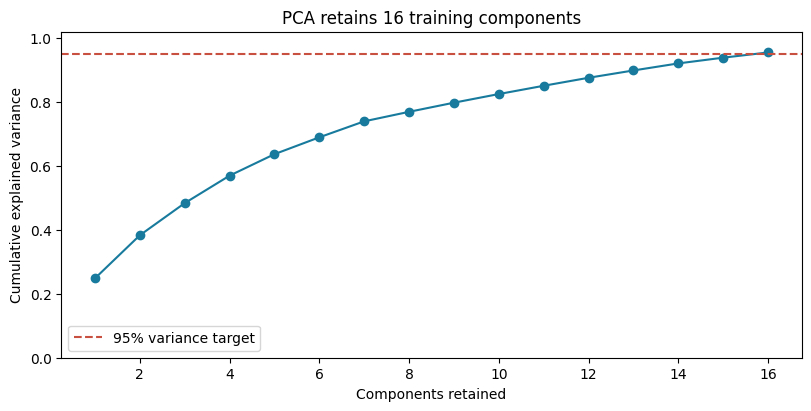

In [ ]:
pca_variant = next(name for name in searches if name.endswith(' + PCA'))
pca = searches[pca_variant].best_estimator_.named_steps['pca']
cumulative = np.cumsum(pca.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
ax.plot(np.arange(1, len(cumulative) + 1), cumulative, marker='o', color='#187B9D')
ax.axhline(.95, color='#C85041', linestyle='--', label='95% variance target')
ax.set(xlabel='Components retained', ylabel='Cumulative explained variance',
       title=f'PCA retains {pca.n_components_} training components',
       ylim=(0, 1.02))
ax.legend()
save_figure(fig, 'pca_explained_variance.png')


## 4. Hold out a capture day

**Code cell 10**

**What it does.** Retrains model variants on other days and checks performance on one entire capture day at a time.

**Import.** `product` from `itertools` generates every pairing of the three models with the two PCA options.

| Code | What to say |
|---|---|
| `CAPTURE_PARAMS` | Fix algorithm settings for this experiment. The holdout day is not used to search for settings. |
| `days.groupby('capture_day')`, `.ne(day)` | Group the full day's rows for testing and select all other known days for training. All files from one weekday stay together. Unknown filenames are excluded. |
| `pd.MultiIndex.from_frame(holdout[FEATURES])`, `.isin(...)` | Treat a feature row as a multi-column key. Find training keys also present in the test day and remove those training rows. |
| `drop_duplicates(FEATURES)`, `nunique() < 2` | Deduplicate the remaining training rows and skip a fold if training lacks one of the two classes. |
| `make_pipeline(...).set_params(...)`, `.fit()` | Build a fresh preprocessing pipeline and model for each day and variant. Learn from the development set only. |
| `int(truth.sum())` | Count actual attacks because the labels are binary. |
| `if positives else np.nan` | Leave recall, F1 and AP undefined for a test day with no attacks. Monday still supports measuring false alarms. |
| `test_attack_families`, `training_overlap_removed` | Record the families represented on the held-out day and the number of matching training rows removed. |
| `pivot(...)`, `dropna(how='all')`, `reindex(...)` | Reshape recall to one row per day and one column per variant, omit days with no defined recall and sort the chart by weekday. |

**Viva answer.** “Boosting without PCA caught **56.42%** of Friday attacks and **0.31%** of Tuesday attacks. The capture-day experiment exposes changes in traffic and attack mix that a random split can hide. It cannot isolate the cause of the drop.”

Friday: testing 45,070 flows, removed 1,516 matching training rows
Monday: testing 10,232 flows, removed 1,006 matching training rows
Thursday: testing 8,851 flows, removed 937 matching training rows
Tuesday: testing 18,022 flows, removed 746 matching training rows
Wednesday: testing 19,667 flows, removed 1,079 matching training rows


,day,model,pca,train_rows,test_rows,training_overlap_removed,test_attacks,test_attack_families,accuracy,precision,recall,f1,average_precision,false_positive_rate,tn,fp,fn,tp
0,Friday,Logistic regression,False,54898,45070,1516,13601,"BOT, DDOS, PORTSCAN",0.8748,0.8187,0.7516,0.7837,0.8767,0.0719,29205,2264,3379,10222
1,Friday,Logistic regression + PCA,True,54898,45070,1516,13601,"BOT, DDOS, PORTSCAN",0.8240,0.6855,0.7699,0.7253,0.8453,0.1527,26664,4805,3129,10472
2,Friday,Random forest,False,54898,45070,1516,13601,"BOT, DDOS, PORTSCAN",0.8664,0.9899,0.5629,0.7177,0.8600,0.0025,31391,78,5945,7656
3,Friday,Random forest + PCA,True,54898,45070,1516,13601,"BOT, DDOS, PORTSCAN",0.8497,0.9855,0.5093,0.6715,0.8739,0.0032,31367,102,6674,6927
4,Friday,Histogram gradient boosting,False,54898,45070,1516,13601,"BOT, DDOS, PORTSCAN",0.8628,0.9688,0.5635,0.7125,0.8981,0.0078,31222,247,5937,7664
5,Friday,Histogram gradient boosting + PCA,True,54898,45070,1516,13601,"BOT, DDOS, PORTSCAN",0.8543,0.9369,0.5544,0.6966,0.9028,0.0161,30961,508,6060,7541
6,Monday,Logistic regression,False,89736,10232,1006,0,,0.8259,0.0000,NaN,NaN,NaN,0.1741,8451,1781,0,0
7,Monday,Logistic regression + PCA,True,89736,10232,1006,0,,0.7283,0.0000,NaN,NaN,NaN,0.2717,7452,2780,0,0
8,Monday,Random forest,False,89736,10232,1006,0,,0.9912,0.0000,NaN,NaN,NaN,0.0088,10142,90,0,0
9,Monday,Random forest + PCA,True,89736,10232,1006,0,,0.9912,0.0000,NaN,NaN,NaN,0.0088,10142,90,0,0


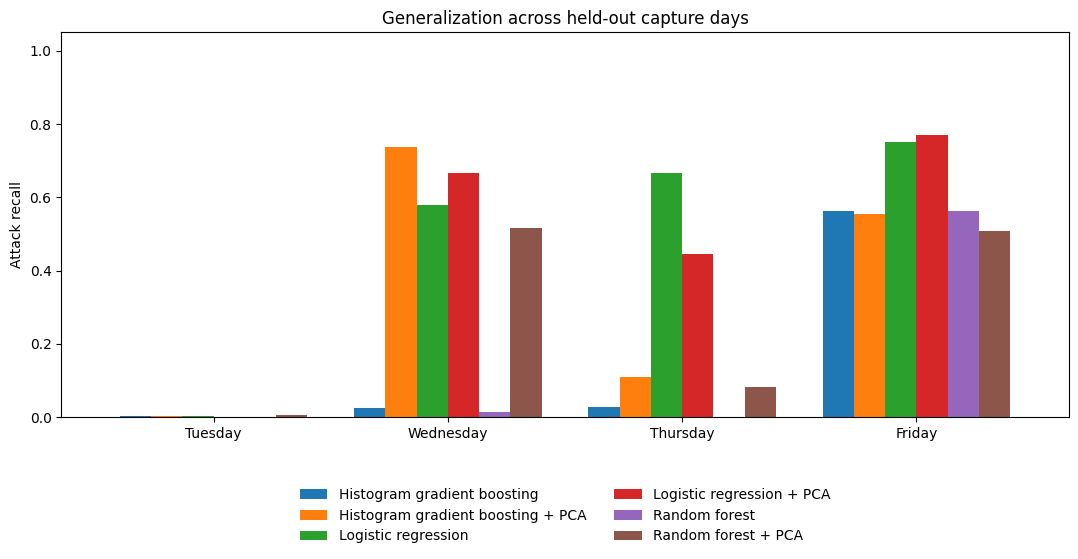

In [ ]:
from itertools import product

CAPTURE_PARAMS = {
    'Logistic regression': {'model__C': 1.0},
    'Random forest': {'model__max_depth': 12, 'model__min_samples_leaf': 2},
    'Histogram gradient boosting': {'model__max_leaf_nodes': 31, 'model__l2_regularization': 1.0},
}
days = day_data.loc[day_data['capture_day'].ne('Unknown')].copy()
day_records = []
for day, holdout in days.groupby('capture_day'):
    development = days.loc[days['capture_day'].ne(day)]
    held_vectors = pd.MultiIndex.from_frame(holdout[FEATURES])
    seen_in_test = pd.MultiIndex.from_frame(development[FEATURES]).isin(held_vectors)
    development = development.loc[~seen_in_test].drop_duplicates(FEATURES)
    if development['target'].nunique() < 2:
        print(f'{day}: skipped because the remaining training set has fewer than two classes.')
        continue
    print(f'{day}: testing {len(holdout):,} flows, removed {seen_in_test.sum():,} matching training rows')
    truth = holdout['target']
    positives = int(truth.sum())
    for name, use_pca in product(models, (False, True)):
        model, _, scaling = models[name]
        estimator = make_pipeline(model, scaling, use_pca).set_params(**CAPTURE_PARAMS[name])
        estimator.fit(development[FEATURES], development['target'])
        pred = estimator.predict(holdout[FEATURES])
        probabilities = estimator.predict_proba(holdout[FEATURES])[:, 1]
        tn, fp, fn, tp = confusion_matrix(truth, pred, labels=[0, 1]).ravel()
        day_records.append({
            'day': day, 'model': f'{name} + PCA' if use_pca else name,
            'pca': use_pca, 'train_rows': len(development), 'test_rows': len(holdout),
            'training_overlap_removed': int(seen_in_test.sum()), 'test_attacks': positives,
            'test_attack_families': ', '.join(sorted(holdout.loc[truth.eq(1), 'family'].unique())),
            'accuracy': accuracy_score(truth, pred), 'precision': precision_score(truth, pred, zero_division=0),
            'recall': recall_score(truth, pred) if positives else np.nan,
            'f1': f1_score(truth, pred) if positives else np.nan,
            'average_precision': average_precision_score(truth, probabilities) if positives else np.nan,
            'false_positive_rate': fp / (tn + fp) if (tn + fp) else np.nan,
            'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
        })

day_comparison = pd.DataFrame(day_records)
if day_comparison.empty:
    print('Capture-day evaluation needs CSVs from multiple named capture days.')
else:
    day_comparison.to_csv(OUTPUT_DIR / 'capture_day_comparison.csv', index=False)
    display(day_comparison.round(4))
    attack_recall = day_comparison.pivot(index='day', columns='model', values='recall').dropna(how='all')
    attack_recall = attack_recall.reindex([
        day for day in ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
        if day in attack_recall.index
    ])
    if not attack_recall.empty:
        ax = attack_recall.plot.bar(figsize=(13, 5), rot=0, ylim=(0, 1.05), width=.8)
        ax.set(xlabel='', ylabel='Attack recall', title='Generalization across held-out capture days')
        ax.legend(loc='upper center', bbox_to_anchor=(.5, -.15), ncol=2, frameon=False)
        save_figure(ax.figure, 'capture_day_recall.png')

## 5. Interpretation and export

**Code cell 11**

**What it does.** Writes the experiment summary and packages the result files into a ZIP. No new imports. It reuses `platform`, `shutil`, `pd`, `np` and `sklearn`.

- `comparison.iloc[0]` takes the highest-CV-AP row because the comparison table was already sorted that way. It does not rank by test accuracy.
- `cv_train_ap - cv_validation_ap` measures the train–validation AP gap on random folds. A small gap there does not establish cross-day reliability.
- The `notes` list gathers data counts, prevalence, metrics, hyperparameters, versions, rejected-label totals and capture-day evaluation counts.
- In an f-string, `:,` formats thousands with commas, `:.4f` gives four decimal places and `:.2%` formats a fraction as a percentage.
- `'\n'.join(notes)` creates one Markdown string. `write_text(..., encoding='utf-8')` saves it.
- `shutil.make_archive('api_shield_results', 'zip', OUTPUT_DIR)` archives the results directory and returns the ZIP path. The last two prints show the summary and where to download the archive.

**Viva prompt.** “What would you need to reproduce the experiment?” → The same CSVs, notebook, sampling settings, seed and recorded package versions.

In [ ]:
best = comparison.iloc[0]
gap = best['cv_train_ap'] - best['cv_validation_ap']
notes = [
    '# API Shield experiment results', '',
    f'Data: CICIDS2017, {len(seen_digests)} distinct CSV files, {len(data):,} modeling flows.',
    f'Train: {len(train):,}. Holdout: {len(test):,}. Holdout attack prevalence: {y_test.mean():.2%}.',
    f'Selected model: {winner}. Mean CV average precision: {best.cv_validation_ap:.4f}.',
    f'Train minus validation average precision: {gap:.4f}.',
    f'Holdout average precision: {best.test_ap:.4f}. F1: {best.f1:.4f}.',
    f'Holdout false alarms: {best.fp}. Missed attacks: {best.fn}.',
    f'Selected hyperparameters: {best.parameters}.',
    f'Environment: Python {platform.python_version()}, pandas {pd.__version__}, '
    f'NumPy {np.__version__}, scikit-learn {sklearn.__version__}.',
    f'Excluded invalid or missing labels: {rejected_df.rows.sum():,}.',
    f'Capture-day model evaluations: {len(day_comparison):,}.',
    'See model_comparison.csv, attack_family_recall.csv and capture_day_comparison.csv for available results.',
]
report = '\n'.join(notes) + '\n'
(OUTPUT_DIR / 'experiment_summary.md').write_text(report, encoding='utf-8')
archive = shutil.make_archive('api_shield_results', 'zip', OUTPUT_DIR)
print(report)
print(f'Exported {archive}')

## Verified run on the uploaded CSVs

The audit processed **2,660,377 raw rows across seven distinct CSVs** and retained **100,165** flows for the random-split experiment after sampling and cleaning. One identical upload, 19,934 repeated feature rows, and 13,903 rows with conflicting labels were excluded from that modeling population. All labels in the distinct uploaded CSVs passed validation.

### Random holdout

| Variant | Accuracy | Attack recall | F1 | Average precision |
|---|---:|---:|---:|---:|
| Histogram gradient boosting | 99.64% | 99.55% | 0.9942 | 0.9997 |
| Random forest | 99.64% | 99.42% | 0.9942 | 0.9996 |
| Histogram gradient boosting + PCA | 99.32% | 99.30% | 0.9890 | 0.9991 |
| Random forest + PCA | 99.43% | 99.16% | 0.9907 | 0.9993 |
| Logistic regression | 88.75% | 96.40% | 0.8407 | 0.9557 |
| Logistic regression + PCA | 81.86% | 91.47% | 0.7564 | 0.8492 |

The PCA variants retained **16 components**. All three recorded lower random-holdout F1 with PCA. Histogram gradient boosting was selected by training cross-validation average precision.

### Held-out capture days

The table shows attack recall for histogram gradient boosting, the random-split winner, with the fixed capture-evaluation settings. The full six-variant results are generated in Section 4.

| Held-out capture | Test attacks | Recall | Recall with PCA | False-positive rate | False-positive rate with PCA |
|---|---:|---:|---:|---:|---:|
| Monday | 0 | — | — | 0.71% | 1.23% |
| Tuesday | 7,820 | 0.31% | 0.27% | 0.68% | 0.78% |
| Wednesday | 9,391 | 1.90% | 55.69% | 0.12% | 0.15% |
| Thursday | 36 | 2.78% | 19.44% | 0.96% | 9.44% |
| Friday | 13,600 | 56.42% | 56.17% | 1.09% | 1.81% |

Monday contains only benign flows in the test fold, so attack recall is undefined. The checks above apply to the uploaded input files and the recorded Python 3.12, pandas 2.2.3 and scikit-learn 1.9.1 run. Colab regenerates the plots and reports from the files in its runtime.
